# Assignment No.01

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from scipy.ndimage import gaussian_filter
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [8]:
import pandas as pd
df=pd.read_csv("01_mnist_784.csv")

In [9]:
df.head()

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784,class
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9


In [10]:
X = df.drop(columns="class")
y = df['class']

In [11]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (70000, 784)
Shape of y: (70000,)


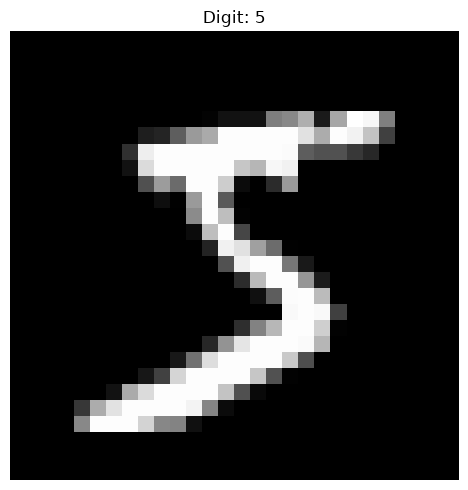

In [13]:
plt.figure(figsize=(10,5))
plt.imshow(X.iloc[0].values.reshape(28,28), cmap='gray')
plt.title(f"Digit: {y.iloc[0]}")
plt.axis('off')
plt.tight_layout()
plt.show()


In [14]:
X=X/255.0

In [15]:
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42)

In [16]:
rf=RandomForestClassifier(n_estimators=200,random_state=42)

In [17]:
rf.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [18]:
y_pred=rf.predict(X_test)

In [19]:
accuracy=accuracy_score(y_test,y_pred)

In [20]:
print(accuracy)

0.9669714285714286


In [21]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1714
           1       0.99      0.99      0.99      1977
           2       0.95      0.97      0.96      1761
           3       0.96      0.95      0.95      1806
           4       0.96      0.97      0.97      1587
           5       0.97      0.96      0.96      1607
           6       0.98      0.98      0.98      1761
           7       0.97      0.97      0.97      1878
           8       0.96      0.95      0.95      1657
           9       0.95      0.95      0.95      1752

    accuracy                           0.97     17500
   macro avg       0.97      0.97      0.97     17500
weighted avg       0.97      0.97      0.97     17500



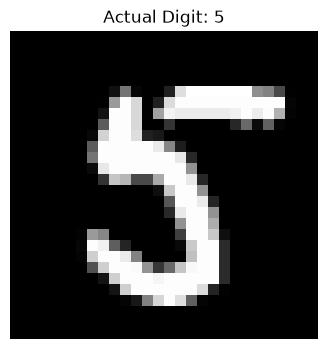

In [25]:
index = 15
image = X_test.iloc[index].values.reshape(28, 28) 

plt.figure(figsize=(4,4))
plt.imshow(image, cmap='gray')
plt.title(f"Actual Digit: {y_test.iloc[index]}")
plt.axis('off')
plt.show()


In [27]:
single_sample = X_test.iloc[index].values.reshape(1, -1)
prediction = rf.predict(single_sample)
print("Actual Digit   :", y_test.iloc[index])
print("Predicted Digit:", prediction[0])

Actual Digit   : 5
Predicted Digit: 5


/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


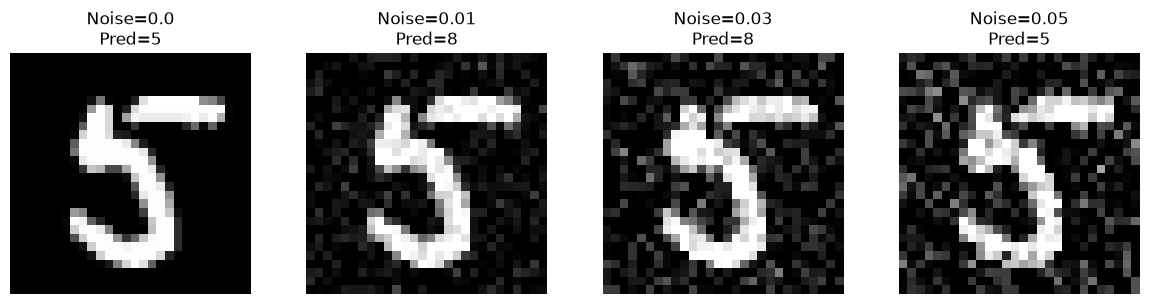

In [30]:
from skimage.util import random_noise
import numpy as np
normalized_image = image / 255.0 if image.max() > 1.0 else image

noise_levels = [0.00, 0.01, 0.03, 0.05]
plt.figure(figsize=(12, 3))

for i, noise in enumerate(noise_levels):
    noisy = random_noise(normalized_image, mode='gaussian', var=noise)
    prediction_input = (noisy * 255.0).reshape(1, -1)
    
    pred = rf.predict(prediction_input)
    
    plt.subplot(1, 4, i + 1)
    plt.imshow(noisy, cmap='gray')
    plt.title(f"Noise={noise}\nPred={pred[0]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Assignment No. 02

In [1]:
import pandas as pd

In [2]:
df=pd.read_csv("02_dataset_phishing - 02_dataset_phishing.csv")

In [3]:
df.sample(5)

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
4926,http://5dabestani.mihanblog.com,31,24,0,2,0,0,0,0,0,...,1,1,0,766,5808,3255580,0,0,3,legitimate
3204,https://hnhkzevk.firebaseapp.com/,33,24,0,2,0,0,0,0,0,...,1,0,0,82,2840,0,0,1,2,phishing
3469,http://www.jjscdc.cn/adfile/login.html,38,13,0,3,0,0,0,0,0,...,1,0,0,953,-1,0,0,1,0,phishing
1671,http://www.thefreedictionary.com/portal,39,25,0,2,0,0,0,0,0,...,1,1,0,2506,6259,682,0,0,6,legitimate
3595,http://terrehautedivorcelawyer.com/EPAY/NOTEPU...,71,27,0,1,0,0,0,0,0,...,1,0,0,299,431,8509505,0,1,0,phishing


In [5]:
df.isnull().sum()

url                0
length_url         0
length_hostname    0
ip                 0
nb_dots            0
                  ..
web_traffic        0
dns_record         0
google_index       0
page_rank          0
status             0
Length: 89, dtype: int64

In [7]:
df.columns

Index(['url', 'length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens',
       'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore',
       'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma',
       'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com',
       'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url',
       'ratio_digits_host', 'punycode', 'port', 'tld_in_path',
       'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains',
       'prefix_suffix', 'random_domain', 'shortening_service',
       'path_extension', 'nb_redirection', 'nb_external_redirection',
       'length_words_raw', 'char_repeat', 'shortest_words_raw',
       'shortest_word_host', 'shortest_word_path', 'longest_words_raw',
       'longest_word_host', 'longest_word_path', 'avg_words_raw',
       'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand',
       'brand_in_subdomain', 'brand_in_path', 'suspecious_tld',
       'statistical_report', 

In [6]:
df['status'].value_counts()

status
legitimate    5715
phishing      5715
Name: count, dtype: int64

In [9]:
X = df[['domain_age', 'google_index', 'page_rank', 'nb_dots', 'ip', 'length_url', 'nb_hyphens', 'nb_at', 'domain_registration_length']]
y = df['status']

In [10]:
X.head()

,domain_age,google_index,page_rank,nb_dots,ip,length_url,nb_hyphens,nb_at,domain_registration_length
0,-1,1,4,3,0,37,0,0,45
1,5767,1,2,1,1,77,0,0,77
2,4004,1,0,4,1,126,1,0,14
3,-1,0,3,2,0,18,0,0,62
4,8175,0,6,2,0,55,2,0,224


In [11]:
y.head()

0    legitimate
1      phishing
2      phishing
3    legitimate
4    legitimate
Name: status, dtype: str

In [12]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [13]:
y_encoded = le.fit_transform(y)

In [16]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(X,y_encoded,test_size=0.20,random_state=42)

In [17]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

In [33]:
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,accuracy_score

In [41]:
lr=LogisticRegression()

In [42]:
lr.fit(x_train_scaled,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [43]:
y_pred=lr.predict(x_test_scaled)

In [44]:
print("Accuracy")
print(accuracy_score(y_test,y_pred))

Accuracy
0.894575678040245


In [45]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.90      0.89      0.90      1157
           1       0.89      0.90      0.89      1129

    accuracy                           0.89      2286
   macro avg       0.89      0.89      0.89      2286
weighted avg       0.89      0.89      0.89      2286



In [50]:
ordered_columns = [
    'domain_age',
    'google_index',
    'page_rank',
    'nb_dots',
    'ip',
    'length_url',
    'nb_hyphens',
    'nb_at',
    'domain_registration_length'
]
new = {
    'domain_age': 12,
    'google_index': 0,
    'page_rank': 0,
    'nb_dots': 1,
    'ip': 0,
    'length_url': 30,
    'nb_hyphens': 2,
    'nb_at': 0,
    'domain_registration_length': 365,
}

X_new = pd.DataFrame([new], columns=ordered_columns)

numeric_prediction = lr.predict(X_new)
final_prediction = le.inverse_transform(numeric_prediction)

print(f"Numerical Prediction: {numeric_prediction[0]}")
print(f"Decoded Human-Readable Status: {final_prediction[0]}")


Numerical Prediction: 1
Decoded Human-Readable Status: phishing


/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


# Assigbment No.03

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

In [33]:
df = pd.read_csv("03_phishing_email.csv")

In [34]:
df.head(5)

,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


In [35]:
X_train, X_test, y_train, y_test = train_test_split(
df['text_combined'], df['label'], test_size=0.25, random_state=42, stratify=df['label']
  )

In [36]:
vectorizer = TfidfVectorizer(lowercase=True, stop_words='english')
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

In [37]:
svm_model = SVC(kernel='linear', C=1.0)

In [38]:
svm_model.fit(X_train_tfidf, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [42]:
y_pred = svm_model.predict(X_test_tfidf)

In [43]:
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}\n")

Accuracy Score: 0.9908



In [45]:
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Phishing']))

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99      9899
    Phishing       0.99      0.99      0.99     10723

    accuracy                           0.99     20622
   macro avg       0.99      0.99      0.99     20622
weighted avg       0.99      0.99      0.99     20622



In [46]:
my_custom_emails = [
    "Hey, what time are we meeting for dinner tonight?", 
    "CONGRATULATIONS! You won a free iPhone! Click here to claim your reward now", 
    "Can you please review the attached document before the morning meeting?", 
    "Urgent: Your account is suspended. Send your bank details immediately to u"
]


In [47]:
my_custom_vectors = vectorizer.transform(my_custom_emails)

In [48]:
predictions = svm_model.predict(my_custom_vectors)

In [49]:
for email, pred in zip(my_custom_emails, predictions):
    result = "PHISHING" if pred == 1 else "LEGITIMATE"
    print(f"Result: {result} -> Email: \"{email}\"")

Result: LEGITIMATE -> Email: "Hey, what time are we meeting for dinner tonight?"
Result: PHISHING -> Email: "CONGRATULATIONS! You won a free iPhone! Click here to claim your reward now"
Result: LEGITIMATE -> Email: "Can you please review the attached document before the morning meeting?"
Result: PHISHING -> Email: "Urgent: Your account is suspended. Send your bank details immediately to u"


# Assignment No.04

In [50]:
import pandas as pd
import numpy as np
import re
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [51]:
df=pd.read_csv("04_pwlds_full.csv")

In [52]:
df.head()

,Password,Strength_Level
0,7hqwv,0
1,cjml,0
2,asuy,0
3,kcyth,0
4,whcq,0


In [54]:
df.columns

Index(['Password', 'Strength_Level'], dtype='str')

In [68]:
df['Strength_Level'].value_counts()

Strength_Level
3    3000975
0    3000072
1    3000048
2    3000026
4    3000000
Name: count, dtype: int64

In [60]:
dictionary_words=[
"password","admin","welcome","hello","football","qwerty"
]

In [61]:

def extract_features(password):
    password = str(password)
    length = len(password)
    digits = sum(c.isdigit() for c in password)
    uppercase = sum(c.isupper() for c in password)
    special = len(re.findall(r'[^A-Za-z0-9]', password))
    dictionary = int(any(word in password.lower() for word in dictionary_words))
    return [length, digits, uppercase, special, dictionary]


In [62]:
feature_names = ['length', 'digits', 'uppercase', 'special', 'has_dict_word']
X = pd.DataFrame(df['Password'].apply(extract_features).tolist(), columns=feature_names)
y = df['Strength_Level']

In [63]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

In [64]:
model=RandomForestClassifier(n_estimators=100,random_state=42)
model.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [65]:
y_pred=model.predict(X_test)

In [66]:
print("Accuracy",accuracy_score(y_test,y_pred))
print("\nClassification Report\n")
print(classification_report(y_test,y_pred))

Accuracy 0.9283760305061599

Classification Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    899839
           1       0.92      0.91      0.91    900358
           2       0.86      0.90      0.88    899618
           3       0.87      0.83      0.85    900576
           4       1.00      1.00      1.00    899946

    accuracy                           0.93   4500337
   macro avg       0.93      0.93      0.93   4500337
weighted avg       0.93      0.93      0.93   4500337



In [67]:
test_passwords = [
"abc123",
"Admin@123",
"Strong#Pass2025",
"hello123",
"Qwerty@1"
]
print("\nPassword Strength Prediction:")
for pwd in test_passwords:
    features = [extract_features(pwd)]
    prediction = model.predict(features)[0]
    print(f"{pwd:20} -> {prediction}")


Password Strength Prediction:
abc123               -> 1
Admin@123            -> 3
Strong#Pass2025      -> 3
hello123             -> 1
Qwerty@1             -> 3


/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feat

# Assignment No.05

In [69]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [70]:
IMG_SIZE = (64, 64)
REAL_DIR = "/Users/ajay/Downloads/05_real_and_fake_face/training_real"
FAKE_DIR = "/Users/ajay/Downloads/05_real_and_fake_face/training_fake"

In [71]:
def load_data(real_dir, fake_dir, img_size):
    X = []
    y = []
    if os.path.exists(real_dir):
        for filename in os.listdir(real_dir):
            path = os.path.join(real_dir, filename)
            img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                img = cv2.resize(img, img_size)
                img = img / 255.0
                features = img.flatten()
                X.append(features)
                y.append(1)
    else:
        print(" Real folder not found!")
    # Load FAKE images
    if os.path.exists(fake_dir):
        for filename in os.listdir(fake_dir):
            path = os.path.join(fake_dir, filename)
            img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                img = cv2.resize(img, img_size)
                img = img / 255.0
                features = img.flatten()
                X.append(features)
                y.append(0)
    else:
        print("Fake folder not found!")
    return np.array(X), np.array(y)

In [72]:
X, y = load_data(
REAL_DIR,
FAKE_DIR,
IMG_SIZE
)
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2041, 4096)
y shape: (2041,)


In [73]:
print("\nClass Distribution:")
print("Fake images :", np.sum(y == 0))
print("Real images :", np.sum(y == 1))


Class Distribution:
Fake images : 960
Real images : 1081


In [74]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

Training samples: 1632
Testing samples : 409


In [75]:
model = SVC(kernel="linear")
model.fit(X_train, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [76]:
y_pred = model.predict(X_test)

In [77]:
accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

0.5256723716381418


In [78]:
print(
classification_report(
y_test,
y_pred,
target_names=["Fake (0)", "Real (1)"]
)
)

              precision    recall  f1-score   support

    Fake (0)       0.50      0.53      0.51       192
    Real (1)       0.56      0.52      0.54       217

    accuracy                           0.53       409
   macro avg       0.53      0.53      0.53       409
weighted avg       0.53      0.53      0.53       409



In [79]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[102  90]
 [104 113]]


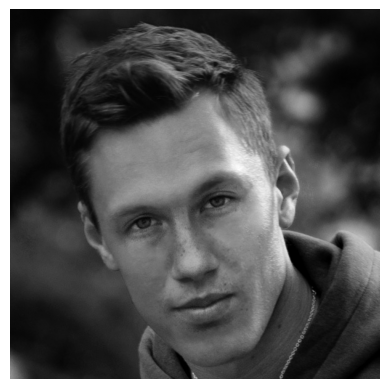

Prediction: Fake


In [80]:
img = cv2.imread("/Users/ajay/Downloads/05_real_and_fake_face/training_fake/mid_456_1111.jpg", cv2.IMREAD_GRAYSCALE)
plt.imshow(img, cmap="gray"); plt.axis("off"); plt.show()
img = cv2.resize(img, IMG_SIZE).flatten() / 255.0
print("Prediction:", "Real" if model.predict([img])[0] == 1 else "Fake")

# Assignment No.06

In [81]:
import hashlib
import base64

In [82]:
def secure_user_input(raw_text):
    if not raw_text or not raw_text.strip():
        return {"error": "No input provided"}
    
    sha256_hash = hashlib.sha256(raw_text.encode('utf-8')).hexdigest()
    encoded_bytes = base64.b64encode(raw_text.encode('utf-8'))
    secure_token = f"ENC_{encoded_bytes.decode('utf-8')}"
    secured_payload = {
        "status": "secured",
        "hash": sha256_hash,
        "token": secure_token
    }
    del raw_text
    return secured_payload

In [86]:
user_message = "MySuperSecretPin123"
print(f"User Input Received: {user_message}\n")

security_result = secure_user_input(user_message)

print("Secure Output Logs")
print(f"SHA-256 (Save to Database for login checks): {security_result['hash']}")
print(f"Base64 Encoded Token (Caution: Decodable): {security_result['token']}")


User Input Received: MySuperSecretPin123

Secure Output Logs
SHA-256 (Save to Database for login checks): 0b3bf9a2c5d2eea3ec12aa35529c0bcabae3c9b65d83e8e72e18c0ef4830d2d5
Base64 Encoded Token (Caution: Decodable): ENC_TXlTdXBlclNlY3JldFBpbjEyMw==


# Assignment No.07

In [105]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [106]:
model = tf.keras.applications.MobileNetV3Small(
    input_shape=(224, 224, 3),
    weights="imagenet"
)

In [107]:
def predict_image(path):
    image = Image.open(path).convert("RGB")
    resized_image = image.resize((224, 224))

    x = np.array(resized_image, dtype=np.float32)
    x = tf.keras.applications.mobilenet_v3.preprocess_input(x)
    x = np.expand_dims(x, axis=0)

    prediction = model.predict(x, verbose=0)

    results = tf.keras.applications.mobilenet_v3.decode_predictions(
        prediction, top=5
    )[0]

    return [
        {
            "class": name,
            "confidence": float(score)
        }
        for _, name, score in results
    ]

In [108]:
image_path = "dog.jpg"

results = predict_image(image_path)

image = Image.open(image_path).convert("RGB")

prediction_text = "\n".join(
    f'{r["class"]}: {r["confidence"]:.4f}'
    for r in results
)

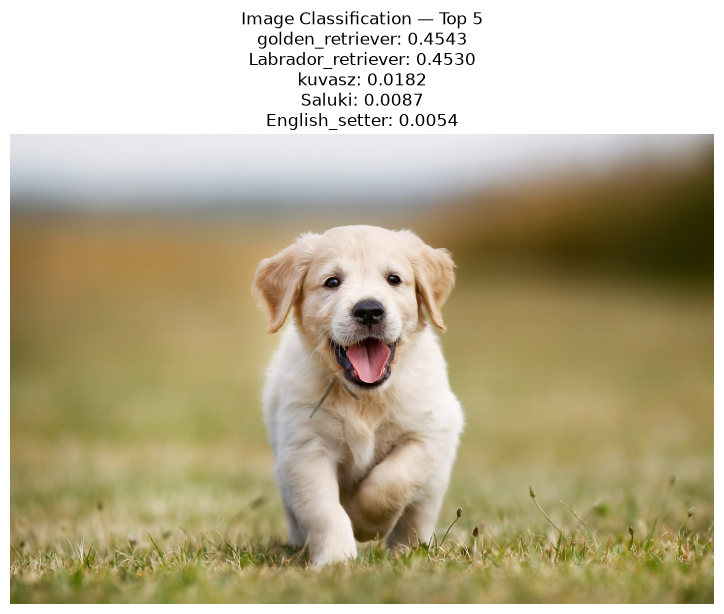

5 PREDICTIONS
golden_retriever = 0.4543
Labrador_retriever = 0.453
kuvasz = 0.0182
Saluki = 0.0087
English_setter = 0.0054


In [109]:
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.title("Image Classification — Top 5\n" + prediction_text)
plt.axis("off")
plt.tight_layout()
plt.show()

print("5 PREDICTIONS")
for r in results:
    print(r["class"], "=", round(r["confidence"], 4))

In [110]:
leaky_response = predict_image("dog.jpg")
print(leaky_response)

[{'class': 'golden_retriever', 'confidence': 0.45432591438293457}, {'class': 'Labrador_retriever', 'confidence': 0.453006774187088}, {'class': 'kuvasz', 'confidence': 0.018200170248746872}, {'class': 'Saluki', 'confidence': 0.008694021962583065}, {'class': 'English_setter', 'confidence': 0.005404388997703791}]


In [111]:
protected_response = {
"class": leaky_response[0]["class"]
}
print(protected_response)

{'class': 'golden_retriever'}


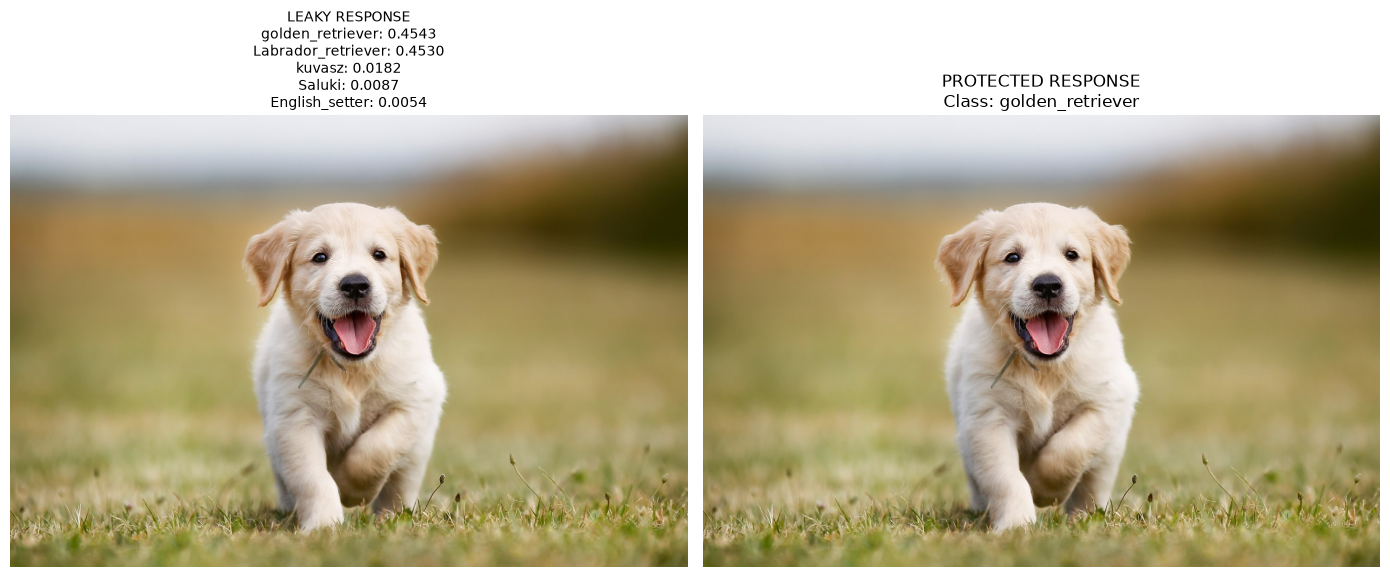

In [112]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(image)
axes[0].axis("off")
axes[0].set_title(
    "LEAKY RESPONSE\n" +
    "\n".join(
        f'{r["class"]}: {r["confidence"]:.4f}'
        for r in leaky_response
    ),
    fontsize=10
)

axes[1].imshow(image)
axes[1].axis("off")
axes[1].set_title(
    "PROTECTED RESPONSE\n" +
    f'Class: {protected_response["class"]}',
    fontsize=12
)

plt.tight_layout()
plt.show()

# Assignment No.09

In [117]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [118]:
df=pd.read_csv("dataset_09 - dataset_09.csv")

In [119]:
df.sample(5)

,0,tcp,ftp_data,SF,491,0.1,0.2,0.3,0.4,0.5,...,25,0.17,0.03,0.17.1,0.25,0.26,0.27,0.05,0.28,normal
4496,0,tcp,ftp_data,SF,383.0,0.0,0.0,0.0,0.0,0.0,...,26.0,0.17,0.03,0.17,0.00,0.0,0.0,0.05,0.00,normal
15667,0,tcp,http,REJ,0.0,0.0,0.0,0.0,0.0,0.0,...,244.0,1.00,0.00,0.50,0.13,0.0,0.0,1.00,0.79,normal
5790,0,udp,private,SF,1.0,0.0,0.0,0.0,0.0,0.0,...,160.0,0.63,0.05,1.00,0.00,0.0,0.0,0.00,0.00,satan
7463,4,tcp,smtp,SF,2936.0,331.0,0.0,0.0,0.0,0.0,...,113.0,0.44,0.02,0.00,0.00,0.0,0.0,0.00,0.00,normal
15804,0,tcp,http,SF,306.0,1320.0,0.0,0.0,0.0,0.0,...,255.0,1.00,0.00,0.01,0.01,0.0,0.0,0.00,0.00,normal


In [120]:
df.columns

Index(['0', 'tcp', 'ftp_data', 'SF', '491', '0.1', '0.2', '0.3', '0.4', '0.5',
       '0.6', '0.7', '0.8', '0.9', '0.10', '0.11', '0.12', '0.13', '0.14',
       '0.15', '0.16', '0.18', '2', '2.1', '0.19', '0.20', '0.21', '0.22', '1',
       '0.23', '0.24', '150', '25', '0.17', '0.03', '0.17.1', '0.25', '0.26',
       '0.27', '0.05', '0.28', 'normal'],
      dtype='str')

In [121]:
df.isnull().sum()

0           0
tcp         1
ftp_data    1
SF          1
491         1
0.1         1
0.2         1
0.3         1
0.4         1
0.5         1
0.6         1
0.7         1
0.8         1
0.9         1
0.10        1
0.11        1
0.12        1
0.13        1
0.14        1
0.15        1
0.16        1
0.18        1
2           1
2.1         1
0.19        1
0.20        1
0.21        1
0.22        1
1           1
0.23        1
0.24        1
150         1
25          1
0.17        1
0.03        1
0.17.1      1
0.25        1
0.26        1
0.27        1
0.05        1
0.28        1
normal      1
dtype: int64

# Assignment No 10

In [133]:
import sys
sys.modules['pandas'] = None # Force pytesseract to skip loading pandas
import os
import random
import cv2
import pytesseract
from PIL import Image, ImageDraw

In [136]:
width, height = 150, 50 
image = Image.new("RGB", (width, height), color=(255, 255, 255)) 
draw = ImageDraw.Draw(image) 

captcha_text = "".join(random.choices("ABCDEFGHJKLMNPQRSTUVWXYZ23456789", k=4)) 

draw.text((20, 15), captcha_text, fill=(0, 0, 0)) 
raw_filename = "captcha.png" 
image.save(raw_filename) 

print(f"Generated CAPTCHA text: {captcha_text}")

Generated CAPTCHA text: DEWB


In [139]:
img = cv2.imread(raw_filename, cv2.IMREAD_GRAYSCALE)

_, thresh = cv2.threshold(img, 150, 255, cv2.THRESH_BINARY)

clean_filename = "captcha_clean.png"
cv2.imwrite(clean_filename, thresh)
print(f"Preprocessed image saved as: {clean_filename}")

Preprocessed image saved as: captcha_clean.png


In [140]:
clean_image = Image.open(clean_filename)
custom_config = r"--psm 7"

extracted_text = pytesseract.image_to_string(clean_image, config=custom_config)

extracted_text_clean = extracted_text.strip()

print(f"Original Text: {captcha_text}")
print(f"OCR Extracted: {extracted_text_clean}\n")

if captcha_text == extracted_text_clean:
    print("Result: CAPTCHA successfully broken!")
else:
    print("Result: CAPTCHA resisted the attack (OCR mismatch).")

TesseractNotFoundError: tesseract is not installed or it's not in your PATH. See README file for more information.